# Laboratorio 5: Análisis de datos de entrada y bondad de ajuste
## Numerales 5.1 (conjunto de datos) y 5.2 (análisis de datos de entrada)

**Curso:** Simulación Computacional · Universidad de los Llanos · **Estudiante:** Duván Felipe Baquero · **Código:** 160005002

Guía FO-DOC-112 (Práctica N.º 04: *Análisis de datos de entrada y ajuste de datos a distribuciones de
probabilidad*). El numeral 5.3 (ajuste de curvas) está en el cuaderno independiente
`Lab5_5.3_AjusteCurvas_160005002.ipynb`, como pide la guía.

Los cuatro archivos `dataset-A.txt` a `dataset-D.txt` traen una muestra de 200 valores cada uno de cuatro procesos
estocásticos. Si no están en la misma carpeta del cuaderno (por ejemplo en Colab), la celda de carga los descarga
de los enlaces de Google Drive de la guía.

In [1]:
%matplotlib inline
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.graphics import tsaplots
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.width", 200)

def guardar(nombre):
    # guarda la figura para el informe solo si existe la carpeta 'figuras'
    if os.path.isdir("figuras"):
        plt.savefig(f"figuras/{nombre}.pdf", bbox_inches="tight")

In [2]:
# enlaces de la guía (Google Drive)
IDS = {"A": "1xYqg1BCxDQH542_Njz0s7tzay6dIG_VO", "B": "1W-pHCurCQFaJ_ydv5BDYsWDxg2-2dxZX",
       "C": "10B8Y6i1H_1J8cFeLoufWTVTtztthYSXj", "D": "1LysY3NL4fFamvChMtPQNrKaXaNMfN_44"}

def cargar(letra):
    nombre = f"dataset-{letra}.txt"
    for ruta in [nombre, os.path.join("conjunto de datos", nombre)]:
        if os.path.exists(ruta):
            return np.loadtxt(ruta)
    url = f"https://drive.google.com/uc?export=download&id={IDS[letra]}"
    urllib.request.urlretrieve(url, nombre)
    return np.loadtxt(nombre)

datos = {L: cargar(L) for L in "ABCD"}
for L, x in datos.items():
    print(f"dataset-{L}: {len(x)} valores; primeros 5 = {np.round(x[:5], 4)}")

dataset-A: 200 valores; primeros 5 = [0.021  0.0814 0.1562 0.1494 0.1934]
dataset-B: 200 valores; primeros 5 = [0.1521 0.0356 0.804  0.0073 0.0352]
dataset-C: 200 valores; primeros 5 = [ 1.6159  0.9267  1.1669 16.6765 19.678 ]
dataset-D: 200 valores; primeros 5 = [0.4637 0.2135 8.4562 8.1297 1.3658]


---
## 5.1 Conjunto de datos: estadística descriptiva

Para cada conjunto se calculan el tamaño de la muestra, el mínimo, el máximo, la media, la varianza y la
desviación estándar muestrales (con $n-1$) y los percentiles 25, 50 y 75. Se agregan la asimetría, la curtosis
(en exceso) y el coeficiente de variación, que ayudan a leer la forma de cada distribución.

In [3]:
def descripcion(x):
    return {"Tamaño de la muestra": len(x),
            "Mínimo": x.min(), "Máximo": x.max(), "Media": x.mean(),
            "Varianza": x.var(ddof=1), "Desviación estándar": x.std(ddof=1),
            "Percentil 25% (Q1)": np.percentile(x, 25),
            "Percentil 50% (Q2 o mediana)": np.percentile(x, 50),
            "Percentil 75% (Q3)": np.percentile(x, 75)}

tabla1 = pd.DataFrame({f"Dataset {L}": descripcion(x) for L, x in datos.items()})
tabla1.index.name = "Medida estadística"
tabla1

,Dataset A,Dataset B,Dataset C,Dataset D
Medida estadística,,,,
Tamaño de la muestra,200.0000,200.0000,200.0000,200.0000
Mínimo,0.0210,0.0001,0.9267,0.1115
Máximo,0.2990,1.5513,6669.8531,17.9670
Media,0.1950,0.2054,762.3938,2.0605
Varianza,0.0019,0.0525,852169.6630,5.4130
Desviación estándar,0.0438,0.2291,923.1304,2.3266
Percentil 25% (Q1),0.1638,0.0463,152.9121,0.6343
Percentil 50% (Q2 o mediana),0.1921,0.1377,455.5576,1.4064
Percentil 75% (Q3),0.2301,0.2902,1028.5909,2.5289


In [4]:
forma = pd.DataFrame({f"Dataset {L}": {"Asimetría (skewness)": stats.skew(x),
                                        "Curtosis (exceso)": stats.kurtosis(x),
                                        "Coef. de variación": x.std(ddof=1) / x.mean(),
                                        "Media / mediana": x.mean() / np.median(x)}
                      for L, x in datos.items()})
forma

,Dataset A,Dataset B,Dataset C,Dataset D
Asimetría (skewness),-0.2895,2.4064,2.4821,3.1596
Curtosis (exceso),0.3090,7.9741,9.1009,14.0891
Coef. de variación,0.2246,1.1154,1.2108,1.1291
Media / mediana,1.0154,1.4919,1.6735,1.4651


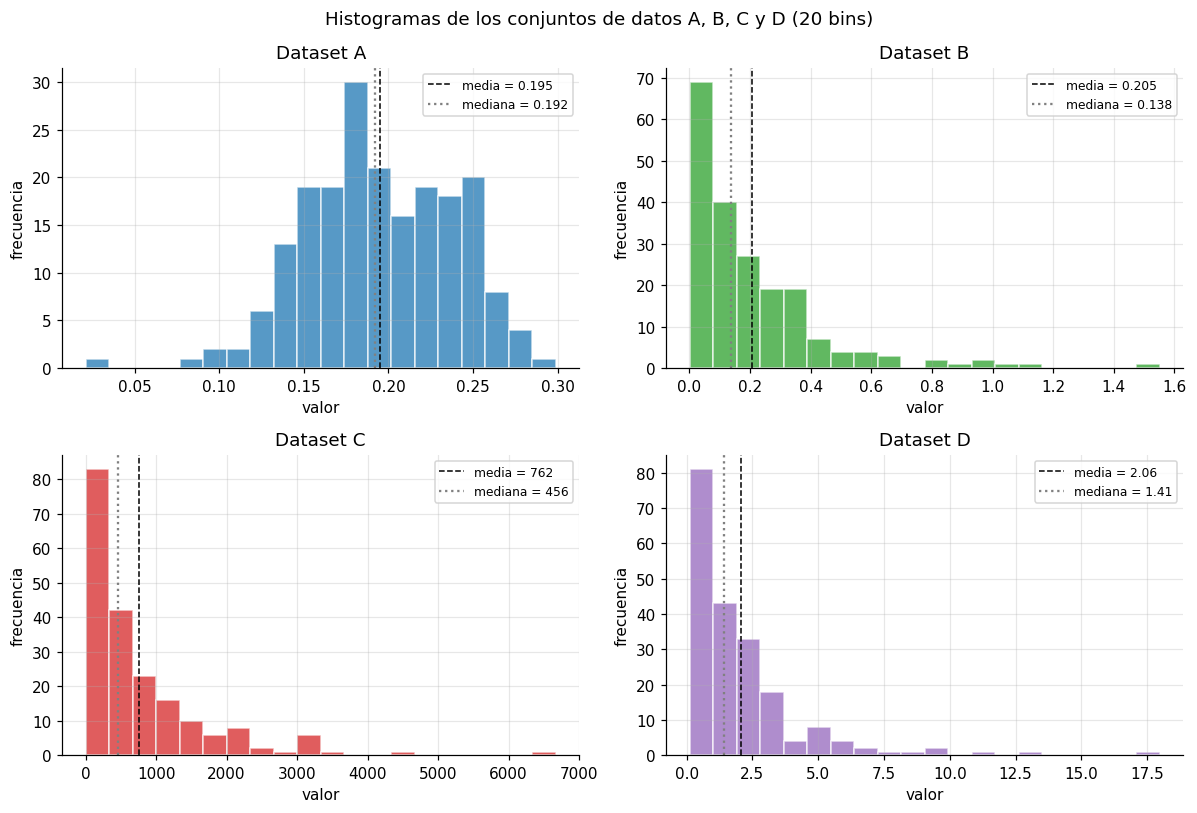

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7.5))
colores = {"A": "#1f77b4", "B": "#2ca02c", "C": "#d62728", "D": "#9467bd"}
for ax, (L, x) in zip(axs.ravel(), datos.items()):
    ax.hist(x, bins=20, color=colores[L], alpha=0.75, edgecolor="white")
    ax.axvline(x.mean(), color="black", ls="--", lw=1, label=f"media = {x.mean():.3g}")
    ax.axvline(np.median(x), color="gray", ls=":", lw=1.5, label=f"mediana = {np.median(x):.3g}")
    ax.set_title(f"Dataset {L}"); ax.set_xlabel("valor"); ax.set_ylabel("frecuencia")
    ax.legend(fontsize=8)
plt.suptitle("Histogramas de los conjuntos de datos A, B, C y D (20 bins)")
plt.tight_layout(); guardar("51_histogramas"); plt.show()


### ¿Qué puede analizar de las medidas de estadística descriptiva y los histogramas?

A primera vista hay dos grupos. El conjunto A es el único con forma de campana: la media (0,1950) y la mediana
(0,1921) casi coinciden, la asimetría es leve y negativa ($-0{,}29$) y los datos están concentrados en un rango
corto, entre 0,021 y 0,299, con un coeficiente de variación de solo 0,22. Además, el valor 0,021 está bastante
separado del resto (el siguiente más pequeño es 0,081) y es justamente el primero de la secuencia. Por su forma
acotada y casi simétrica, A apunta a distribuciones como la normal o la beta.

B, C y D tienen la forma típica de los tiempos entre llegadas: muchos valores pequeños y una cola larga
hacia la derecha. En los tres la media supera a la mediana entre un 47 % y un 67 %, la asimetría pasa de 2,4 y el
coeficiente de variación está entre 1,12 y 1,21.

- En B la media (0,2054) y la desviación estándar (0,2291) son casi iguales, que es la huella de una
  exponencial (en ella media y desviación coinciden, con asimetría 2 y curtosis 6; aquí salen 2,41 y 7,97). La
  barra más alta del histograma está pegada al cero.
- D tiene una cola todavía más pesada: asimetría 3,16 y curtosis 14,1, bastante por encima de lo que daría
  una exponencial, y su mínimo es 0,11, no cero. Eso sugiere una lognormal o una gamma más que una exponencial.
- C se parece en forma a B y D, pero está en otra escala: va de 0,93 a 6669,85, con media 762 y varianza
  852 170. El histograma por sí solo no muestra nada raro, pero en el numeral 5.2 se ve que esa forma esconde un
  cambio fuerte de nivel a lo largo de la secuencia.

Un detalle curioso: A y B tienen media cercana a 0,2, como los conjuntos artificiales del cuaderno de ejemplo
del profesor (tasa de llegadas de 5). Con la estadística descriptiva y el histograma no se puede saber si los
valores son independientes o si el proceso cambia en el tiempo, porque ambas herramientas ignoran el orden de los
datos. Eso es lo que revisa el siguiente numeral.


---
## 5.2 Análisis de datos de entrada

Se usan las funciones del cuaderno de ejemplo *Example. Input Data Analysis.ipynb*. Igual que allí, cada valor
se interpreta como un tiempo entre llegadas, de modo que la suma acumulada da los instantes de llegada. Cambios
respecto al ejemplo:

- En el ejemplo el horizonte es $T = 200$ porque los datos artificiales se generaron en 200 unidades de tiempo.
  Aquí no se conoce, así que se toma $T$ igual a la suma de los 200 valores (el instante de la última llegada).
- `plotArrivalCountsIntervals` guardaba el conteo del intervalo $k$ en `counts[k-1]`, de modo que el primer
  intervalo terminaba en la última barra. Se corrigió el índice y se cuentan las llegadas con
  `np.histogram`, que incluye los bordes.
- La media móvil del ejemplo usa una ventana de 100, pensada para series de unas 1000 llegadas. Con 200 datos
  esa ventana promedia media muestra a la vez y aplana todo, así que se usa una ventana de 20.
- Las funciones dibujan sobre ejes que se les pasan, para poder juntar las gráficas de un conjunto en una sola
  figura.

Además de las gráficas se calculan tres indicadores numéricos: la autocorrelación de retraso 1 con su banda del
95 % ($\pm 1{,}96/\sqrt{n}$), la prueba de Ljung-Box con 10 retrasos (independencia) y la correlación de
Spearman entre el valor y su posición en la secuencia (tendencia).

In [6]:
def plotSerie(ax, x):
    ax.plot(x, ".", color="#c0392b", ms=4)
    ax.set_title("Secuencia de valores")
    ax.set_xlabel("observación i"); ax.set_ylabel("$x_i$")

def plotLagk(ax, x, lags=20):
    tsaplots.plot_acf(x, lags=lags, zero=False, ax=ax, title="")
    ax.set_title("Correlaciones de retraso estimadas")
    ax.set_xlabel("retraso k"); ax.set_ylabel("correlación")
    ax.set_ylim(-1, 1); ax.set_xlim(0.5, lags + 0.5)

def plotScatter(ax, x):
    ax.scatter(x[:-1], x[1:], marker="^", s=14, alpha=0.7)
    ax.set_title("Diagrama de dispersión")
    ax.set_xlabel("observación k"); ax.set_ylabel("observación k+1")

def plotArrivalTimePattern(ax, x):
    llegadas = np.cumsum(x)
    proporcion = np.arange(1, len(x) + 1) / len(x)
    ax.plot(llegadas, proporcion, "b")
    ax.plot([0, llegadas[-1]], [0, 1], "k--", lw=0.8, label="tasa constante")
    ax.set_title("Patrón de hora de llegada")
    ax.set_xlabel("tiempo T"); ax.set_ylabel("proporción antes de T")
    ax.ticklabel_format(style="sci", axis="x", scilimits=(-3, 3))
    ax.legend(fontsize=7)

def plotArrivalCountsIntervals(ax, x, nbins=40):
    llegadas = np.cumsum(x)
    T = llegadas[-1]
    conteos, bordes = np.histogram(llegadas, bins=nbins, range=(0, T))   # corrección del índice
    ax.bar(np.arange(1, nbins + 1), conteos, width=1, edgecolor="black", color="white")
    ax.axhline(len(x) / nbins, color="gray", ls="--", lw=1)
    ax.set_title(f"Conteo de llegadas: {nbins} intervalos de {T / nbins:.3g}")
    ax.set_xlabel("intervalo"); ax.set_ylabel("conteo")
    return conteos

def plotMovingAvgPlot(ax, x, window=20):
    media_movil = pd.Series(x).rolling(window, center=True, min_periods=window // 2).mean().to_numpy()
    m, s = np.nanmean(media_movil), np.nanstd(media_movil)
    ax.plot(media_movil)
    ax.axhline(m, color="black", lw=1)
    ax.axhline(m + 3 * s, color="green", lw=1); ax.axhline(m - 3 * s, color="green", lw=1)
    ax.set_title(f"Media móvil (ventana de {window})")
    ax.set_xlabel("observación i"); ax.set_ylabel("media móvil")

def analizar(L, x):
    fig, axs = plt.subplots(2, 3, figsize=(15, 8))
    plotSerie(axs[0, 0], x)
    plotLagk(axs[0, 1], x)
    plotScatter(axs[0, 2], x)
    plotArrivalTimePattern(axs[1, 0], x)
    plotArrivalCountsIntervals(axs[1, 1], x)
    plotMovingAvgPlot(axs[1, 2], x)
    plt.suptitle(f"Dataset {L}: evaluación de independencia y estabilidad", fontsize=13)
    plt.tight_layout(); guardar(f"52_dataset{L}"); plt.show()

def indicadores(x):
    r1 = acf(x, nlags=1)[1]
    lb = acorr_ljungbox(x, lags=[10], return_df=True)
    rho, p_rho = stats.spearmanr(np.arange(len(x)), x)
    mitad = len(x) // 2
    return {"r1 (retraso 1)": r1, "banda 95 %": 1.96 / np.sqrt(len(x)),
            "Ljung-Box Q(10)": lb["lb_stat"].iloc[0], "valor p Ljung-Box": lb["lb_pvalue"].iloc[0],
            "Spearman rho (tendencia)": rho, "valor p Spearman": p_rho,
            "media 1.a mitad": x[:mitad].mean(), "media 2.a mitad": x[mitad:].mean()}

### Dataset A

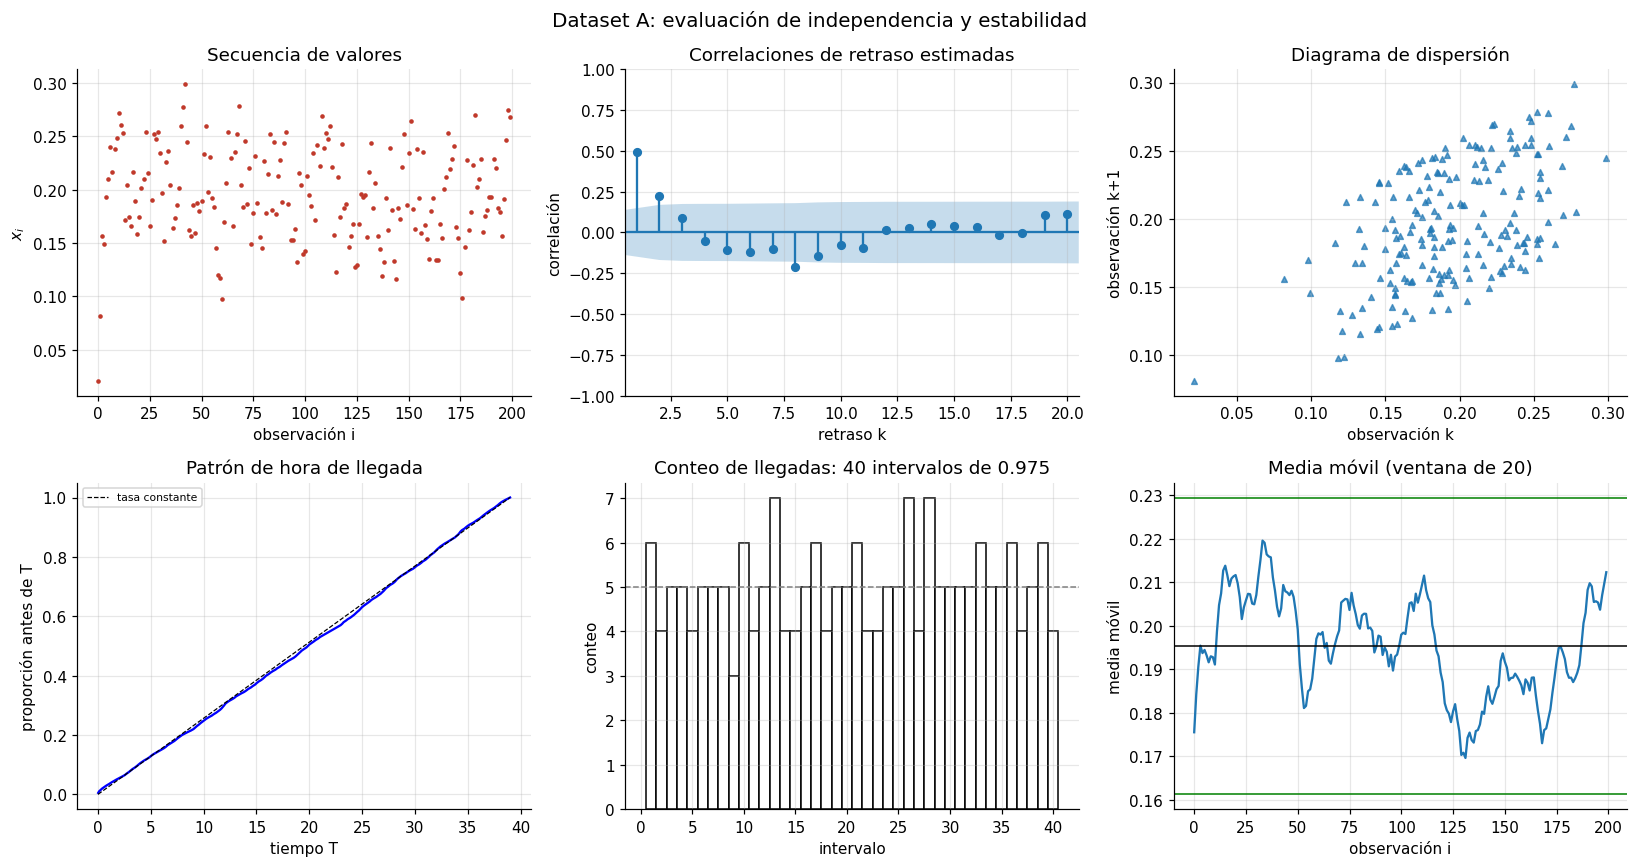

In [7]:
analizar("A", datos["A"])

### Dataset B

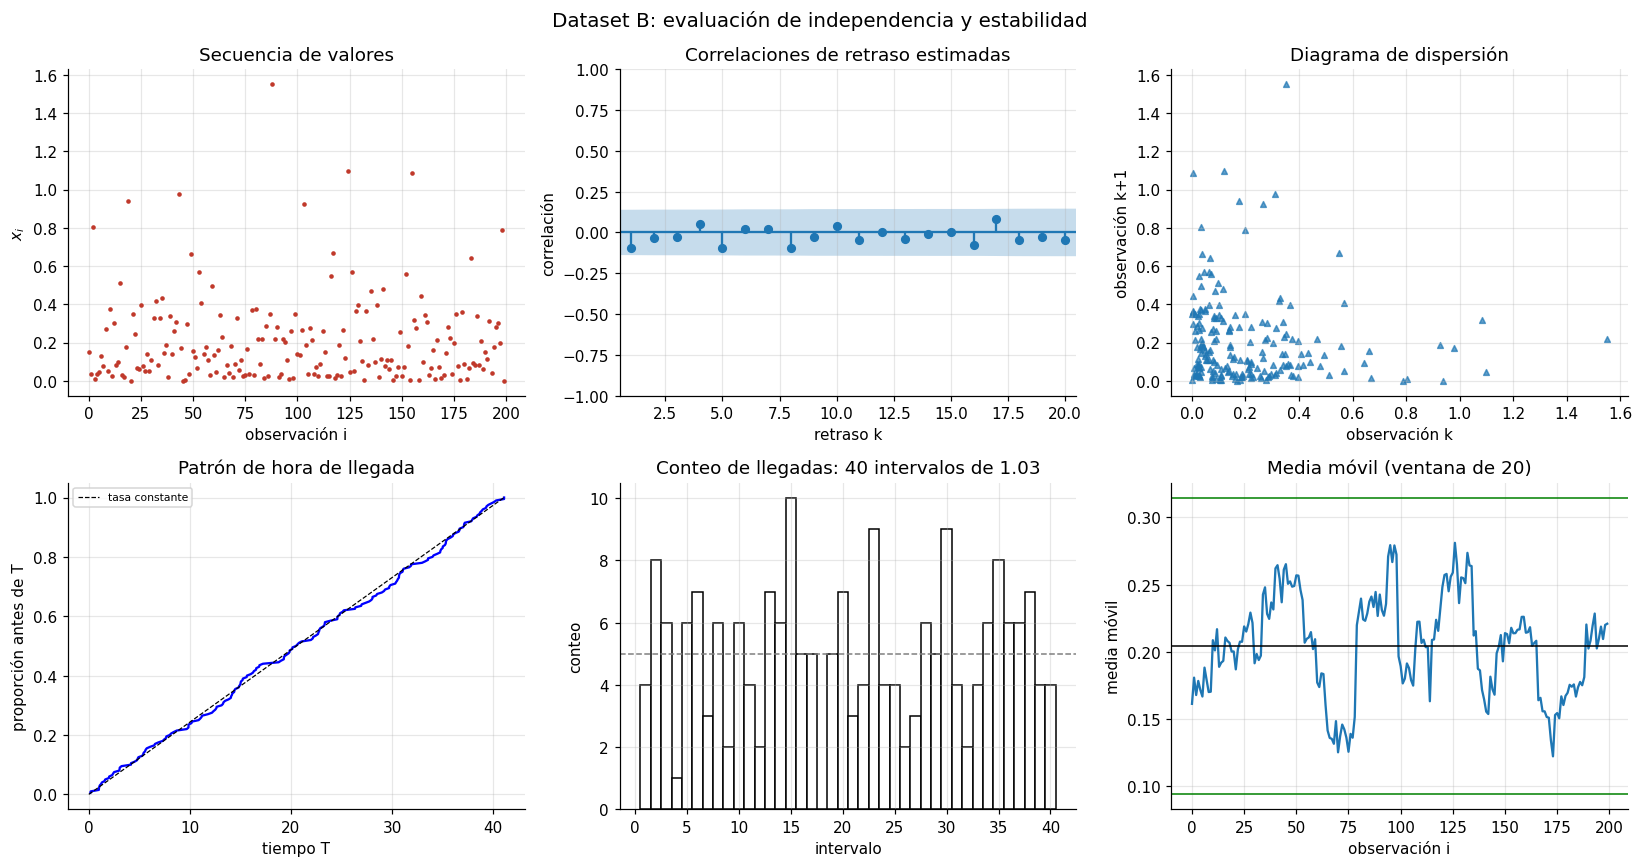

In [8]:
analizar("B", datos["B"])

### Dataset C

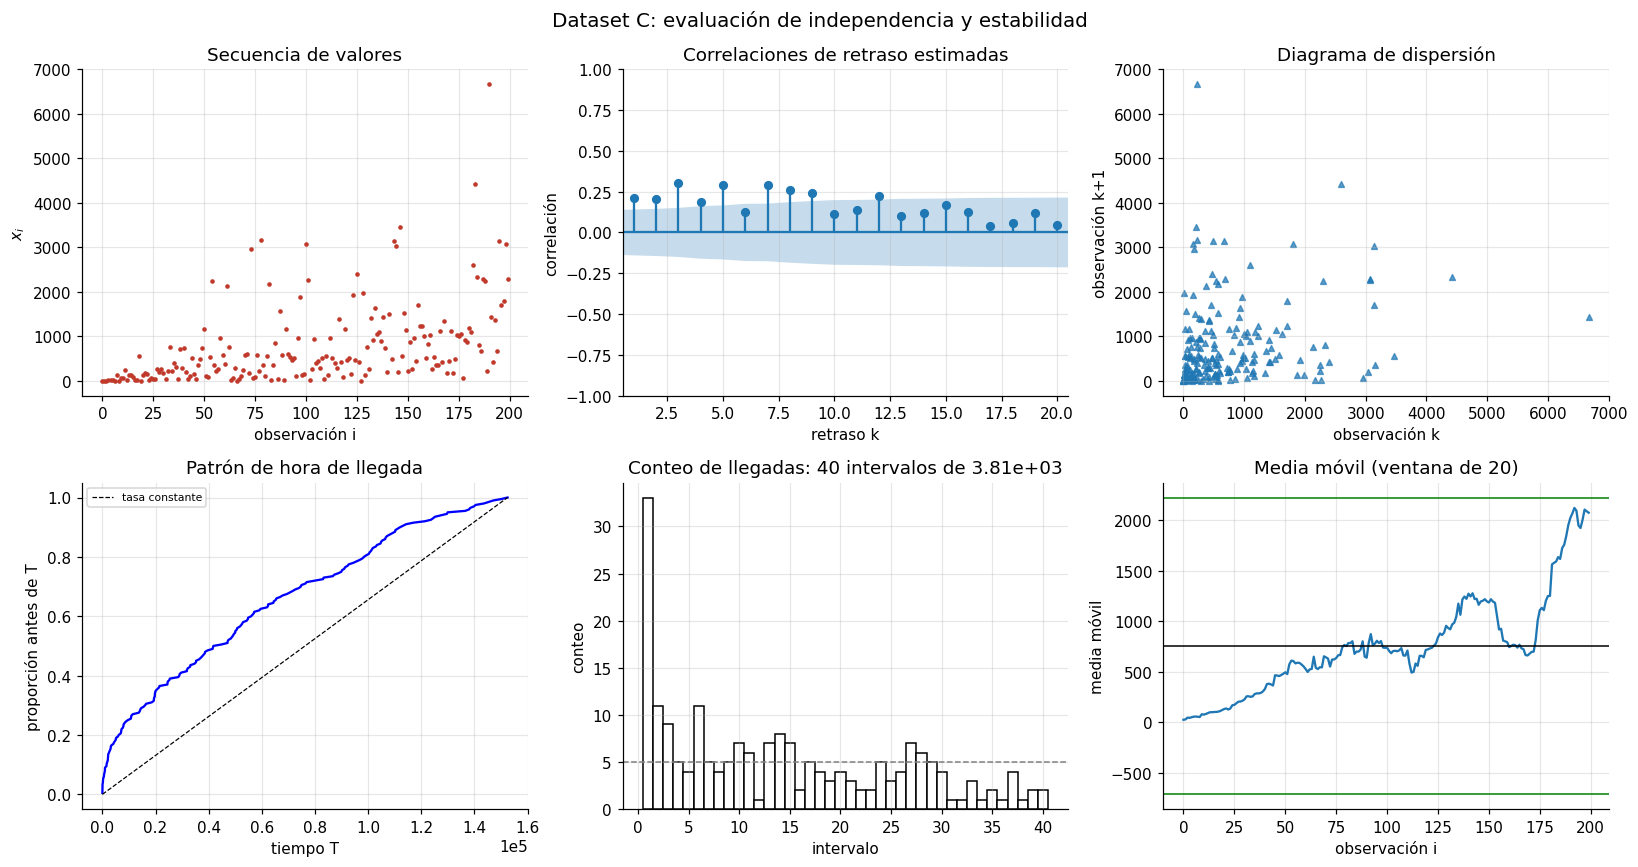

In [9]:
analizar("C", datos["C"])

### Dataset D

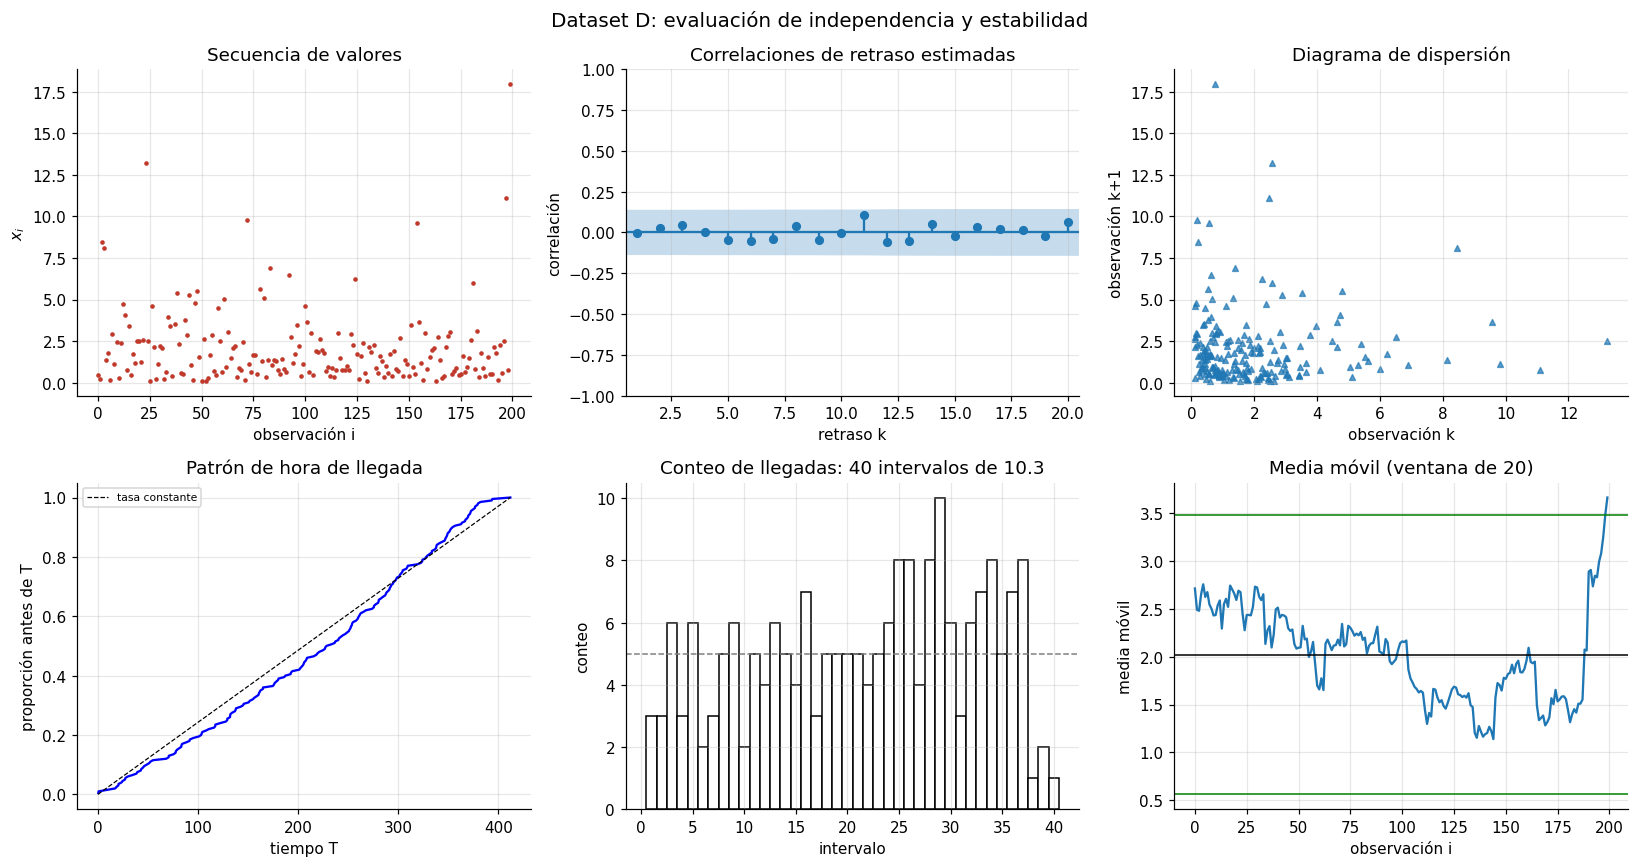

In [10]:
analizar("D", datos["D"])

### Indicadores numéricos de independencia y estabilidad

In [11]:
tabla_ind = pd.DataFrame({f"Dataset {L}": indicadores(x) for L, x in datos.items()})
tabla_ind

,Dataset A,Dataset B,Dataset C,Dataset D
r1 (retraso 1),0.4922,-0.0923,0.2084,-0.0024
banda 95 %,0.1386,0.1386,0.1386,0.1386
Ljung-Box Q(10),83.6925,6.9414,110.8847,2.7106
valor p Ljung-Box,0.0000,0.7310,0.0000,0.9874
Spearman rho (tendencia),-0.1048,-0.0035,0.6034,-0.1171
valor p Spearman,0.1397,0.9610,0.0000,0.0987
media 1.a mitad,0.1988,0.2050,417.5578,2.2830
media 2.a mitad,0.1913,0.2058,1107.2299,1.8380


In [12]:
# medias por quintos de la secuencia, para ver la estabilidad en el tiempo
quintos = pd.DataFrame({f"Dataset {L}": [q.mean() for q in np.array_split(x, 5)] for L, x in datos.items()},
                       index=["obs. 1-40", "41-80", "81-120", "121-160", "161-200"])
quintos

,Dataset A,Dataset B,Dataset C,Dataset D
obs. 1-40,0.1991,0.2000,153.2783,2.5796
41-80,0.1991,0.1910,570.1698,2.1065
81-120,0.2034,0.2246,676.1729,1.8334
121-160,0.1813,0.2344,1060.4579,1.6804
161-200,0.1923,0.1769,1351.8903,2.1026



### ¿Qué se puede determinar de cada conjunto sobre independencia y estabilidad?

#### Dataset A: estacionario, pero correlacionado

La correlación de retraso 1 es 0,49, más de tres veces la banda
del 95 % ($\pm 0{,}139$), y la de retraso 2 (0,22) también la supera; la prueba de Ljung-Box rechaza la
independencia con $p < 0{,}0001$. El diagrama de dispersión lo muestra a simple vista: la nube sube en diagonal, es
decir, a un valor alto le suele seguir otro alto. En cambio, no hay señales de inestabilidad: las medias por quintos
van de 0,181 a 0,203, la correlación de Spearman con la posición no es significativa ($p = 0{,}14$), el patrón de
llegadas va pegado a la diagonal y los conteos por intervalo oscilan alrededor de 5. Es el mismo comportamiento del
conjunto 6 del cuaderno de ejemplo, donde cada valor es una combinación del anterior y un número uniforme; eso
también explica que el primer valor (0,021) sea el mínimo, porque es el valor inicial y no sale de la recurrencia.
Para simular este proceso no basta con ajustar una distribución y sacar valores independientes: habría que
reproducir la dependencia, por ejemplo con un modelo autorregresivo.

#### Dataset B: compatible con IID

Todas las correlaciones de retraso caen dentro de la banda (la de retraso 1 es
$-0{,}09$), Ljung-Box da $p = 0{,}73$ y el diagrama de dispersión no muestra ningún patrón, solo la concentración de
puntos cerca del origen que se espera de una exponencial. La correlación de Spearman con la posición es
prácticamente cero ($p = 0{,}96$), el patrón de llegadas es una línea recta y los conteos fluctúan entre 0 y 10
alrededor de 5, como en un proceso de Poisson. La media móvil sube y baja, pero siempre dentro de los límites. Es
el candidato natural para ajustar una sola distribución.

#### Dataset C: no estacionario

Es el caso más claro de los cuatro. Las medias por quintos pasan de 153 a 570, 676,
1060 y 1352, es decir, la media se multiplica por casi nueve entre el comienzo y el final; Spearman da
$\rho = 0{,}60$ con $p \approx 3 \times 10^{-21}$. La media móvil sube de forma sostenida y el patrón de llegadas
queda muy por encima de la diagonal: si los valores se ven como tiempos entre llegadas, las llegadas se van
espaciando, y por eso 33 de los 200 eventos caen en el primero de los 40 intervalos (lo esperado sería 5) y solo 2
en el último. Las correlaciones de retraso son positivas en todos los retrasos (entre 0,1 y 0,3) y Ljung-Box
rechaza con $p < 0{,}0001$, pero esa correlación es en buena parte un efecto de la tendencia: valores cercanos en el
tiempo se parecen porque comparten el mismo nivel. Ajustar una única distribución a C mezclaría niveles muy
distintos; según el capítulo 3 de [Banks98] habría que modelar la tendencia, por ejemplo con un parámetro que
cambie con el tiempo.

#### Dataset D: compatible con IID, con una salvedad

Las correlaciones están todas dentro de la banda
($r_1 = -0{,}002$) y Ljung-Box da $p = 0{,}99$, así que no hay evidencia de dependencia. La estabilidad es menos
limpia que en B: las medias por quintos bajan de 2,58 a 1,68 y luego suben a 2,10, el patrón de llegadas queda un
poco por debajo de la diagonal en la parte media y la correlación de Spearman es $-0{,}12$, aunque con $p = 0{,}099$
no alcanza a ser significativa al 5 %. El salto de la media móvil al final se debe a que los dos últimos valores son
11,11 y 17,97 (este último, el máximo de toda la muestra) y en el borde la ventana solo promedia 10 datos. Con una
cola tan pesada estas variaciones son esperables, así que D se puede tratar como IID, aunque con más datos convendría
revisar de nuevo la estabilidad.

#### Conclusión del numeral

B y D cumplen el supuesto IID y se les puede ajustar una distribución directamente; A es estacionario
pero dependiente, y C no es estacionario. En el numeral 5.3 se ajustan las ocho distribuciones a los cuatro
conjuntos como pide la guía, pero para A y C la distribución ajustada describe solo la forma global de los datos y
no basta para simular el proceso.
